## Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

## Load Libraries

In [86]:
library(tidyr)
library(dplyr)
library(ggplot2)

# Load Metadata

In [4]:
# Read in metadata
metadata <- read.csv("metadata.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$Gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ MECP2:'data.frame':	32 obs. of  23 variables:
  ..$ Gene                      : chr [1:32] "MECP2" "MECP2" "MECP2" "MECP2" ...
  ..$ Sample_ID                 : chr [1:32] "KB1" "KB2" "KB3" "KB19" ...
  ..$ Sample_Name               : chr [1:32] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3" "CO_R270X_B2_d18_A1" ...
  ..$ Cell_Type                 : chr [1:32] "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" ...
  ..$ Genotype                  : chr [1:32] "MUT" "MUT" "MUT" "MUT" ...
  ..$ Time_Point                : chr [1:32] "D18" "D18" "D18" "D18" ...
  ..$ Group                     : chr [1:32] "R270X_D18" "R270X_D18" "R270X_D18" "R270X_D18" ...
  ..$ Replicate                 : int [1:32] 1 2 3 4 5 6 1 2 3 4 ...
  ..$ Clean_Sample_Name         : chr [1:32] "R270X_D18_1" "R270X_D18_2" "R270X_D18_3" "R270X_D18_4" ...
  ..$ Batch                     : int [1:32] 0 0 0 1 1 1 0 0 0 1 ...
  ..$ D18_MUT_vs_D18_WT         : int 

In [5]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$Group))
}


=== Group counts for MECP2 ===

R270X_D18 R270X_D46 R270X_D90    WT_D18    WT_D46    WT_D90 
        6         4         6         6         5         5 


# Load Counts

In [21]:
# Read in counts
counts <- read.delim("05_gene_counts/MECP2_normalized_counts.txt")

# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata.csv")[, c("Sample_Name", "Clean_Sample_Name")]

# Create mapping
name_mapping <- setNames(mapping_df$Clean_Sample_Name, mapping_df$Sample_Name)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# Select only MECP2
mecp2_rows <- grep("mecp2", rownames(counts), ignore.case = TRUE)
counts <- counts[mecp2_rows, ]

# View
head(counts)

,R270X_D18_1,R270X_D18_2,R270X_D18_3,R270X_D18_4,R270X_D18_5,R270X_D18_6,R270X_D46_1,R270X_D46_2,R270X_D46_3,R270X_D46_4,⋯,WT_D46_1,WT_D46_2,WT_D46_3,WT_D46_4,WT_D46_5,WT_D90_1,WT_D90_2,WT_D90_3,WT_D90_4,WT_D90_5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MECP2,1.428284,2.303148,1.271631,1.519283,1.699721,1.736798,2.133966,1.191005,2.935113,1.588546,⋯,1.249679,2.055473,1.63469,1.614294,1.593424,1.916145,1.442863,1.227395,1.318257,2.568859


# Make MECP2 Expression Box Plot

In [51]:
# Reshape data 
counts_long <- data.frame(
  sample = names(counts),
  expression = as.numeric(counts[1,])
) %>%
  mutate(group = gsub("_\\d+$", "", sample)) %>%
  mutate(date = gsub(".*_", "", group))

# View
head(counts_long)

,sample,expression,group,date
,<chr>,<dbl>,<chr>,<chr>
1,R270X_D18_1,1.428284,R270X_D18,D18
2,R270X_D18_2,2.303148,R270X_D18,D18
3,R270X_D18_3,1.271631,R270X_D18,D18
4,R270X_D18_4,1.519283,R270X_D18,D18
5,R270X_D18_5,1.699721,R270X_D18,D18
6,R270X_D18_6,1.736798,R270X_D18,D18


In [52]:
# Convert date to factor with desired order
counts_long$date <- factor(counts_long$date, levels = c("D18", "D46", "D90"))

# Sort by date, then genotype
counts_long$genotype <- gsub("_.*", "", counts_long$group)

# Create ordered factor
counts_long$group_ordered <- factor(counts_long$group, 
                                     levels = c("WT_D18", "R270X_D18", 
                                                "WT_D46", "R270X_D46",
                                                "WT_D90", "R270X_D90"))

# Replace underscores with spaces for plot labeling
levels(counts_long$group_ordered) <- gsub("_", " ", levels(counts_long$group_ordered))

# Replace R270X with MUT
levels(counts_long$group_ordered) <- gsub("R270X", "MUT", levels(counts_long$group_ordered))

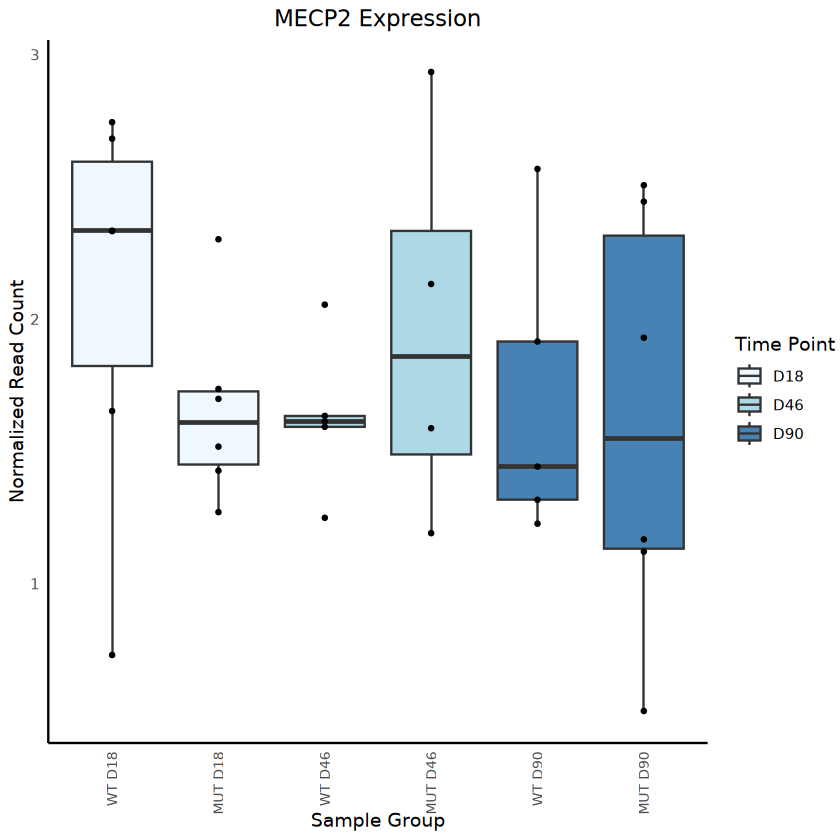

In [84]:
# Create box plot 
p <- ggplot(counts_long, aes(x = group_ordered, y = expression, fill = date)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0, alpha = 1, size = 0.8) +
  theme_minimal() +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 8),
    plot.title = element_text(hjust = 0.5),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line = element_line(color = "black"),
    legend.position = "right"
  ) +
  labs(title = "MECP2 Expression",
      x = "Sample Group",
      y = "Normalized Read Count",
      fill = "Time Point"
  ) +
  scale_fill_manual(values = c("D18" = "aliceblue", 
                               "D46" = "lightblue", 
                               "D90" = "steelblue")) +
  guides(fill = guide_legend(override.aes = list(shape = NA, alpha = 1)))

print(p)

In [85]:
ggsave("MECP2_expression_box_plot.pdf",
  plot = p,
  device = "pdf",
  path = "07_DEG_Figures",
  scale = 1,
  width = 4,
  height = 4,
  units = "in",
  dpi = 600,
  create.dir = TRUE,
)